<!-- d2l:prose id=matrix-state-md-1 fw=all -->

# Matrix-State Recurrences

The selective state space models of that section decide, token by token, what to keep and for how long, yet we have not asked how many distinct associations a fixed-size state can store and retrieve. Much of language modeling requires *associative recall*—binding a key to a value (`rate = 0.05`, or *"Mira is the ship's engineer"*) and retrieving the value hundreds of tokens later when the key reappears. Transformers solve associative recall by keeping every past key and value in a growing KV cache and comparing the query against all of them. Can a recurrent state of fixed size store and retrieve key–value pairs too, and how does its capacity scale with state size?

Yes—when the state is a *matrix* $\mathbf{S}_t \in \mathbb{R}^{d_v \times d_k}$ updated by adding outer products $\mathbf{v}_t \mathbf{k}_t^\top$ and queried by matrix-vector multiplication $\mathbf{S}_t \mathbf{q}_t$. We have already met two instances of this structure: unnormalized linear attention (that section) and the $H \times N$ channel-by-state matrix of Mamba (that section). Below we derive the exact retrieval-error and capacity scaling law of outer-product matrix memories, add an input-dependent scalar decay to forget stale pairs, establish *state space duality* between decayed matrix recurrences and causally masked linear attention, implement the hardware-efficient chunked training algorithm (`chunked_linear_attention`), and test whether trained `GatedLinearAttention` layers obey the theoretical capacity law on multi-query associative recall.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

<!-- d2l:prose id=matrix-state-md-2 fw=all -->

## An Associative Memory

### Writing and Reading Pairs

The simplest associative memory stores pairs by summing outer products. For a toy illustration in $\mathbb{R}^2$, bind orthogonal unit keys $\mathbf{k}_1 = (1, 0)^\top$ and $\mathbf{k}_2 = (0, 1)^\top$ to scalar values $v_1 = 3$ and $v_2 = 5$ in the row vector $\mathbf{S} = v_1 \mathbf{k}_1^\top + v_2 \mathbf{k}_2^\top = (3, 5)$. Multiplying by either key retrieves its value without error: $\mathbf{S}\mathbf{k}_1 = 3$ and $\mathbf{S}\mathbf{k}_2 = 5$. Once we add a third pair $\mathbf{k}_3 = (1, 1)^\top / \sqrt{2}$ with $v_3 = 7$, however, $\mathbf{k}_3$ overlaps $\mathbf{k}_1$ and $\mathbf{k}_2$: $\mathbf{S}$ becomes $(3 + 7/\sqrt{2}, 5 + 7/\sqrt{2}) \approx (7.95, 9.95)$, and querying $\mathbf{k}_1$ returns $7.95$ instead of $3$. Two key dimensions hold at most two orthogonal keys without cross-talk.

In general, with key vectors $\mathbf{k}_t \in \mathbb{R}^{d_k}$, value vectors $\mathbf{v}_t \in \mathbb{R}^{d_v}$, and query vectors $\mathbf{q}_t \in \mathbb{R}^{d_k}$, the state is a matrix $\mathbf{S}_t \in \mathbb{R}^{d_v \times d_k}$ updated and read at each step via:

$$
\mathbf{S}_t = \mathbf{S}_{t-1} + \mathbf{v}_t \mathbf{k}_t^\top, \qquad
\mathbf{y}_t = \mathbf{S}_t \mathbf{q}_t.
$$

Each write adds a rank-one matrix $\mathbf{v}_t \mathbf{k}_t^\top$ mapping the direction $\mathbf{k}_t$ to $\mathbf{v}_t$, where $(\mathbf{q}_t, \mathbf{k}_t, \mathbf{v}_t)$ are learned linear projections of the token representation.

### Linear Attention

Unrolling the equation from $\mathbf{S}_0 = \mathbf{0}$ reveals that an additive matrix recurrence computes unnormalized causal linear attention (that section, @Katharopoulos.Vyas.Pappas.ea.2020):

$$\mathbf{y}_t = \Big(\sum_{s \le t} \mathbf{v}_s \mathbf{k}_s^\top\Big)
\mathbf{q}_t = \sum_{s \le t} (\mathbf{k}_s^\top \mathbf{q}_t)\,
\mathbf{v}_s.$$

Evaluated from the right, each output $\mathbf{y}_t$ weights every past value $\mathbf{v}_s$ by the dot-product similarity $\mathbf{k}_s^\top \mathbf{q}_t$; evaluated from the left, the sum of outer products is carried forward in the fixed-size recurrent state $\mathbf{S}_t \in \mathbb{R}^{d_v \times d_k}$.

### Interference

How many pairs can $\mathbf{S} = \sum_{i=1}^n \mathbf{v}_i \mathbf{k}_i^\top$ store before cross-talk overwhelms the signal? Querying with a stored unit key $\mathbf{k}_j$ ($\|\mathbf{k}_j\| = 1$) separates the target value from the interference of the other $n - 1$ pairs:

$$
\mathbf{S}\mathbf{k}_j = \mathbf{v}_j + \sum_{i \neq j}
(\mathbf{k}_i^\top \mathbf{k}_j)\, \mathbf{v}_i.
$$

Exact zero-error readout requires mutually orthogonal keys, of which $\mathbb{R}^{d_k}$ admits at most $d_k$. For random unit keys, we can compute the expected interference exactly.

**Proposition.** Let $\mathbf{k}_1, \ldots, \mathbf{k}_n$ be independent and uniformly distributed on the unit sphere of $\mathbb{R}^{d_k}$, and let $\mathbf{v}_1, \ldots, \mathbf{v}_n \in \mathbb{R}^{d_v}$ be unit vectors chosen independently of the keys. Then the expected squared retrieval error at every stored key is:

$$
\mathbb{E}\,\big\|\mathbf{S}\mathbf{k}_j - \mathbf{v}_j\big\|^2 =
\frac{n - 1}{d_k}.
$$

**Proof.** Expanding the squared norm of $\sum_{i \neq j} (\mathbf{k}_i^\top \mathbf{k}_j)\mathbf{v}_i$, cross terms with $i \neq l$ vanish in expectation because, conditioned on $\mathbf{k}_j$, $\mathbf{k}_i^\top \mathbf{k}_j$ and $\mathbf{k}_l^\top \mathbf{k}_j$ are independent with mean zero. Since $\|\mathbf{v}_i\|^2 = 1$, there remain $n - 1$ diagonal terms $\mathbb{E}[(\mathbf{k}_i^\top \mathbf{k}_j)^2]$. By rotational symmetry of the unit sphere in $\mathbb{R}^{d_k}$, each coordinate of $\mathbf{k}_i$ has expected square $1/d_k$, so $\mathbb{E}[(\mathbf{k}_i^\top \mathbf{k}_j)^2] = 1/d_k$. Summing over the $n - 1$ interfering pairs gives $(n - 1)/d_k$. $\blacksquare$

Notice that retrieval error depends on the load ratio $(n - 1)/d_k$ and not on *when* a pair was written: an additive memory loses pairs through crowding, not aging.

To test the equation empirically in NumPy, `matrix_memory` writes $n$ pairs of unit keys and codebook values into $\mathbf{S} = \sum_{i=1}^n \mathbf{v}_i \mathbf{k}_i^\top$ (with optional shared-direction correlation $\rho$) and returns both the mean squared retrieval error and nearest-neighbor recall over a 256-vector unit codebook:

In [2]:
def matrix_memory(d_k, nums, rho=0, num_values=256, trials=20, seed=0):
    """Read error and recall of S = sum_i v_i k_i^T over random unit keys."""
    rng = np.random.default_rng(seed)
    unit = lambda X: X / np.linalg.norm(X, axis=-1, keepdims=True)
    codebook = unit(rng.standard_normal((num_values, d_k)))
    errors, recalls = [], []
    for n in nums:
        error = recall = 0
        for _ in range(trials):
            K = unit(rng.standard_normal((n, d_k)))  # Keys as rows
            shared = unit(rng.standard_normal(d_k))  # A common direction
            K = unit(np.sqrt(1 - rho**2) * K + rho * shared)
            ids = rng.integers(0, num_values, n)
            S = codebook[ids].T @ K  # Sum of v_i k_i^T
            reads = K @ S.T  # Row j is S k_j
            error += ((reads - codebook[ids]) ** 2).sum(1).mean() / trials
            recall += ((reads @ codebook.T).argmax(1) == ids).mean() / trials
        errors.append(error)
        recalls.append(recall)
    return errors, recalls

<!-- d2l:prose id=matrix-state-md-3 fw=all -->

We evaluate `matrix_memory` across pair loads $n \in \{8, 16, \ldots, 512\}$ for independent random keys ($d_k \in \{32, 64, 128\}, \rho = 0$) and correlated keys ($d_k = 64, \rho = 0.5$), plotting the squared read errors against the theoretical line $(n - 1)/d_k$:

recall at n =        8   16   32   64  128  256  512
dₖ = 32           1.00 0.99 0.96 0.74 0.39 0.16 0.07
dₖ = 64           1.00 1.00 1.00 1.00 0.96 0.72 0.37
dₖ = 128          1.00 1.00 1.00 1.00 1.00 1.00 0.94
dₖ = 64, ρ = 0.5  1.00 0.99 0.83 0.49 0.21 0.07 0.03


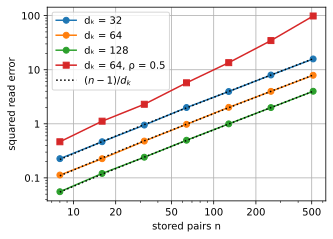

In [3]:
nums = [8, 16, 32, 64, 128, 256, 512]
results = {f'dₖ = {d_k}': matrix_memory(d_k, nums) for d_k in (32, 64, 128)}
results['dₖ = 64, ρ = 0.5'] = matrix_memory(64, nums, rho=0.5)
predictions = [[(n - 1) / d_k for n in nums] for d_k in (32, 64, 128)]
d2l.plot(nums, [err for err, _ in results.values()] + predictions,
         'stored pairs n', 'squared read error',
         legend=list(results) + ['$(n-1)/d_k$'], xscale='log', yscale='log',
         fmts=('-o', '-o', '-o', '-s', 'k:', 'k:', 'k:'), figsize=(5, 3.5))
print('recall at n =    ', ' '.join(f'{n:4d}' for n in nums))
for name, (_, recalls) in results.items():
    print(f'{name:17s}', ' '.join(f'{r:4.2f}' for r in recalls))

<!-- d2l:prose id=matrix-state-md-4 fw=all -->

Two properties jump out from the plot and table:

1. **Recall scales with the total state entries $d_k d_v$:** The squared error curves lie directly on $(n - 1)/d_k$. Yet at $n = d_k = d_v = 64$, where the total squared error is $\approx 1$ (as large as the unit signal $\|\mathbf{v}_j\|^2 = 1$), nearest-neighbor recall is still $1.00$ ($96\%$ at $n = 128$). Why? Because the interference vector is spread isotropically across all $d_v$ value dimensions, so its projection onto any single candidate codebook vector has variance $\approx n / (d_k d_v)$. With $d_v = d_k$, doubling $d_k$ quadruples the state entries $d_k d_v$ and quadruples the number of pairs recalled at a fixed accuracy ($96\%$ at $n = 32$ for $d_k = 32$ and at $n = 128$ for $d_k = 64$; $94\%$ at $n = 512$ for $d_k = 128$; Exercise 5 varies $d_k$ and $d_v$ independently).
2. **Key correlation creates an irreducible error floor:** When keys share a direction with weight $\rho$, pairwise key overlap averages $\approx \rho^2$, yielding expected squared error:

   $$
   \mathbb{E}\,\big\|\mathbf{S}\mathbf{k}_j - \mathbf{v}_j\big\|^2 \approx
   (n - 1)\Big(\rho^4 + \frac{(1 - \rho^2)^2}{d_k}\Big)
   $$

   for zero-mean values (plus a quadratic term in $n$ from the finite-codebook sample mean; see Exercise 4). Because $\rho^4$ does not shrink with $d_k$, correlated keys ($\rho = 0.5$) cut recall at $n = d_k = 64$ from $1.00$ to $0.49$.

## Decay

### Forgetting Old Pairs

Without decay, every pair ever written remains in $\mathbf{S}_t$ with full weight, so interference grows unboundedly with sequence length. Multiplying the state by a scalar decay $a_t \in (0, 1)$ before each write fades older pairs:

$$
\mathbf{S}_t = a_t\, \mathbf{S}_{t-1} + \mathbf{v}_t \mathbf{k}_t^\top,
\qquad a_t \in (0, 1).
$$

At a constant decay $a$, a pair written $\ell$ steps ago carries weight $a^\ell$. The weights sum to $1/(1 - a)$ (an effective window of $1/(1 - a)$ pairs), while the squared weights entering the interference variance sum to $1/(1 - a^2)$, bounding steady-state expected interference by $1 / ((1 - a^2) d_k)$ regardless of total sequence length (Exercise 6). Computing $a_t$ from the input token lets each head hold its state across a span and flush it at topic or clause boundaries. (Related variants use fixed per-head decays in RetNet [@Sun.Dong.Huang.ea.2023], input-dependent scalar decays per head in Mamba-2 [@Dao.Gu.2024], or per-key-coordinate vector decays $\mathbf{S}_{t-1}\textrm{diag}(\boldsymbol{\alpha}_t)$ in Gated Linear Attention [@Yang.Wang.Shen.ea.2024]; we use one input-dependent scalar decay per head.)

### Selective State Space Models as Matrix Memories

Stacking the $H$ channel states $\mathbf{h}_t^{(c)} \in \mathbb{R}^N$ of Mamba's selective SSM (that section, omitting the skip connection $D_c x_{t,c}$) as rows of a matrix $\mathbf{S}_t \in \mathbb{R}^{H \times N}$ reveals that Mamba is already a decayed matrix-state recurrence:

$$
\begin{aligned}
\mathbf{S}_t &= \mathbf{E}_t \odot \mathbf{S}_{t-1} + (\boldsymbol{\Delta}_t
\odot \mathbf{x}_t)\, \mathbf{B}_t^\top, \\
\mathbf{y}_t &= \mathbf{S}_t \mathbf{C}_t, \qquad
\mathbf{E}_t = \exp(\textrm{diag}(\boldsymbol{\Delta}_t)\,
\boldsymbol{\Lambda}).
\end{aligned}
$$

Matching terms against the equation, the value vector is $\mathbf{v}_t = \boldsymbol{\Delta}_t \odot \mathbf{x}_t \in \mathbb{R}^H$, the key vector is $\mathbf{k}_t = \mathbf{B}_t \in \mathbb{R}^N$, and the query vector is $\mathbf{q}_t = \mathbf{C}_t \in \mathbb{R}^N$. The only difference is that Mamba's decay matrix $\mathbf{E}_t \in \mathbb{R}^{H \times N}$ varies across both channels and states; restricting $\mathbf{E}_t$ to a single scalar $a_t$ per head yields Mamba-2 [@Dao.Gu.2024] (Exercise 1) and unlocks the matrix-multiplication dual form below.

## The Dual Form

### Unrolling with Decay

Unrolling the equation from $\mathbf{S}_0 = \mathbf{0}$ shows that a pair written at step $s$ arrives at step $t \ge s$ attenuated by the cumulative decay product $L_{ts} = a_{s+1} a_{s+2} \cdots a_t$:

$$\mathbf{y}_t = \sum_{s \le t} L_{ts}\, (\mathbf{k}_s^\top \mathbf{q}_t)\,
\mathbf{v}_s, \qquad L_{ts} = a_{s+1} a_{s+2} \cdots a_t.$$

Stacking $\mathbf{q}_t, \mathbf{k}_t, \mathbf{v}_t, \mathbf{y}_t$ as rows of $\mathbf{Q}, \mathbf{K}, \mathbf{V}, \mathbf{Y}$ and setting $L_{ts} = 0$ for $s > t$ yields the *dual form*:

$$\mathbf{Y} = (\mathbf{L} \odot \mathbf{Q}\mathbf{K}^\top)\, \mathbf{V}.$$

Equation the equation is causal linear attention with a *learned, input-dependent decay mask* $\mathbf{L}$—a correspondence @Dao.Gu.2024 term *state space duality* (SSD). Evaluating the equation as a step-by-step recurrence takes $O(T d_v d_k)$ work and $O(d_v d_k)$ memory; evaluating it via the full $T \times T$ matrix $\mathbf{L} \odot \mathbf{Q}\mathbf{K}^\top$ runs in parallel matrix multiplications at $O(T^2(d_k + d_v))$ work and $O(T^2)$ memory. Let us write both forms explicitly, starting with the sequential step-by-step recurrence `linear_attention_recurrent`:

In [4]:
def linear_attention_recurrent(Q, K, V, a):
    """y_t = S_t q_t with S_t = a_t S_{t-1} + v_t k_t^T, step by step."""
    S, outputs = Q.new_zeros(V.shape[-1], K.shape[-1]), []
    for q, k, v, a_t in zip(Q, K, V, a):
        S = a_t * S + torch.outer(v, k)
        outputs.append(S @ q)
    return torch.stack(outputs)

<!-- d2l:prose id=matrix-state-md-5 fw=all -->

Next, `decay_mask(log_a)` forms the lower-triangular decay matrix $L_{ts} = \exp(\sum_{r=s+1}^t \log a_r)$ via cumulative sums so `linear_attention_dual` can evaluate $\mathbf{Y} = (\mathbf{L} \odot \mathbf{Q}\mathbf{K}^\top)\mathbf{V}$ across all positions at once:

In [5]:
def decay_mask(log_a):
    """L[t, s] = a_{s+1} * ... * a_t for s <= t, and 0 for s > t."""
    cum = log_a.cumsum(-1)
    log_L = cum[..., :, None] - cum[..., None, :]  # Sum of log a over (s, t]
    causal = torch.ones(log_L.shape[-2:], dtype=torch.bool,
                        device=log_a.device).tril()
    return torch.exp(log_L.masked_fill(~causal, -torch.inf))

def linear_attention_dual(Q, K, V, a):
    """The same outputs as Y = (L * Q K^T) V, all positions at once."""
    return (decay_mask(torch.log(a)) * (Q @ K.T)) @ V

<!-- d2l:prose id=matrix-state-md-6 fw=all -->

### Chunked Computation

Neither pure form is ideal for GPU training: the token-level recurrence runs $T$ tiny sequential steps, while the full dual form materializes a $T \times T$ matrix per head. *Chunking* gets the best of both worlds by partitioning the sequence into $T / m$ chunks of length $m$ (the figure). Because any cross-chunk decay $L_{ts}$ factors into (key decay to the end of its chunk) $\times$ (intermediate chunk decays) $\times$ (query decay from the start of its chunk), every off-diagonal block of $\mathbf{L}$ has rank $1$—and every off-diagonal block of $\mathbf{L} \odot \mathbf{Q}\mathbf{K}^\top$ has rank at most $d_k$, summarized completely by the $d_v \times d_k$ state matrix carried across chunk boundaries (Exercise 2).

![The mask $\mathbf{L}$ of the equation for random decays, partitioned into chunks. Diagonal blocks (outlined in blue) are small masked-attention products computed in parallel. Every block below the diagonal (outlined in orange) has rank one in $\mathbf{L}$ and rank at most $d_k$ in $\mathbf{L} \odot \mathbf{Q}\mathbf{K}^\top$, and is accounted for by the state passed from chunk to chunk (arrows); the shading fades as the decays compound.](../img/mdl-modernrnn-semiseparable.svg)

Indexing positions within each chunk from $1$ to $m$, `chunked_linear_attention` proceeds in three batched steps:

1. **Within chunks (diagonal blocks):** Evaluate the dual form the equation inside each length-$m$ chunk in parallel using its $m \times m$ decay mask.
2. **Across chunks (chunk-boundary states):** Let $\gamma^{(c)} = a_1 \cdots a_m$ be the total decay of chunk $c$. The state at the end of chunk $c$ satisfies the chunk-level linear recurrence

   $$\mathbf{S}^{(c)} = \gamma^{(c)}\, \mathbf{S}^{(c-1)} + \sum_{t=1}^{m}
   L_{mt}\, \mathbf{v}_t \mathbf{k}_t^\top,$$

   which `d2l.linear_scan` evaluates across all $T / m$ chunks in $\lceil \log_2(T/m) \rceil$ rounds.
3. **Past-state readout (off-diagonal blocks):** Add $(a_1 \cdots a_t)\,\mathbf{S}^{(c-1)}\mathbf{q}_t$ to each position $t$ in chunk $c$.

Almost all FLOPs are now dense matrix multiplications, and peak working memory drops from $O(T^2)$ to $O(Tm + (T/m) d_v d_k)$.

In [6]:
def chunked_linear_attention(Q, K, V, log_a, chunk_size):
    """y_t = S_t q_t with S_t = a_t S_{t-1} + v_t k_t^T, computed in chunks.

    Q, K: (batch_size, T, d_k); V: (batch_size, T, d_v); log_a: (batch_size, T)
    """
    B, T, m = Q.shape[0], Q.shape[1], chunk_size
    Q, K, V = (X.reshape(B, T // m, m, -1) for X in (Q, K, V))
    log_a = log_a.reshape(B, T // m, m)
    # 1. Within chunks: the dual form, one m x m mask per chunk
    Y = (decay_mask(log_a) * (Q @ K.mT)) @ V
    # 2. Across chunks: S^(c) = gamma^(c) S^(c-1) + sum_t L_mt v_t k_t^T
    cum = log_a.cumsum(-1).unsqueeze(-1)  # Log decay from the chunk's start
    writes = V.mT @ (K * torch.exp(cum[:, :, -1:] - cum))
    S = d2l.linear_scan(torch.exp(cum[:, :, -1:]), writes)  # At chunk ends
    S = torch.cat([torch.zeros_like(S[:, :1]), S[:, :-1]], 1)  # At the starts
    # 3. Every step reads the state at its chunk's start, decayed to it
    return (Y + (Q * torch.exp(cum)) @ S.mT).reshape(B, T, -1)

<!-- d2l:prose id=matrix-state-md-7 fw=all -->

Let us check that the sequential recurrence, the full dual form, and the chunked algorithm across chunk sizes $m \in \{16, 64, 256\}$ agree to float32 precision on a sequence of length $T = 512$.

In [7]:
gen = torch.Generator().manual_seed(0)  # Local: later training stays unseeded
T, d_k, d_v = 512, 64, 64
Q, K, V = (torch.randn(T, d, generator=gen) for d in (d_k, d_k, d_v))
a = 0.8 + 0.19 * torch.rand(T, generator=gen)  # Decays in (0.8, 0.99)
Y = linear_attention_recurrent(Q, K, V, a)
forms = {'dual form': linear_attention_dual(Q, K, V, a)}
for m in (16, 64, 256):
    forms[f'chunks of {m}'] = chunked_linear_attention(
        Q[None], K[None], V[None], torch.log(a)[None], m)[0]
for name, Y_form in forms.items():
    print(f'{name:13s} relative deviation from the recurrence: '
          f'{(Y_form - Y).abs().max() / Y.abs().max():.1e}')

dual form     relative deviation from the recurrence: 1.5e-06
chunks of 16  relative deviation from the recurrence: 2.2e-07
chunks of 64  relative deviation from the recurrence: 2.5e-07
chunks of 256 relative deviation from the recurrence: 8.8e-07


<!-- d2l:prose id=matrix-state-md-8 fw=all -->

All forms agree to $\sim 10^{-6}$ relative error (Exercise 3 analyzes the optimal chunk size $m$).

## A Gated Linear Attention Layer

### The Layer

`GatedLinearAttention` wraps multi-head chunked linear attention into a sequence mixer. For each head $h$, it computes an input-dependent scalar decay $a_{t,h} = \sigma(\mathbf{w}_h^\top \mathbf{x}_t + b_h)$, with biases initialized via `init_decays` so initial timescales $\tau_h$ ($a_{t,h} \approx e^{-1/\tau_h}$) span $[4, 256]$ steps log-uniformly across heads.

In [8]:
class GatedLinearAttention(nn.Module):
    """Multi-head linear attention with one input-dependent decay per head."""
    def __init__(self, num_hiddens, num_heads, chunk_size=16, conv_width=4,
                 timescales=(4, 256)):
        super().__init__()
        d = num_hiddens
        self.num_heads, self.chunk_size = num_heads, chunk_size
        self.W_qkv = nn.Linear(d, 3 * d, bias=False)
        self.conv = nn.Conv1d(3 * d, 3 * d, conv_width, groups=3 * d,
                              padding=conv_width - 1)  # One filter per channel
        self.W_a = nn.Linear(d, num_heads)  # Decay gate, one per head
        self.W_g = nn.Linear(d, d)  # Output gate
        self.W_o = nn.Linear(d, d, bias=False)
        d2l.init_lecun(self)
        self.init_decays(*timescales)  # Memories of 4 to 256 steps by default

    def init_decays(self, tau_min, tau_max):
        """Start the decays at exp(-1/tau), tau log-uniform in range."""
        b = self.W_a.bias
        tau = torch.logspace(math.log10(tau_min), math.log10(tau_max), len(b))
        with torch.no_grad():  # log sigmoid(b) = -1 / tau
            b.copy_(-torch.log(torch.expm1(1 / tau)))

<!-- d2l:prose id=matrix-state-md-9 fw=all -->

We isolate the memory update in a `memory` method so that section can subclass `GatedLinearAttention` and swap in the delta rule without duplicating the rest of the block. `heads_to_batch` and `batch_to_heads` fold and unfold the head axis into the batch axis.

In [9]:
def heads_to_batch(Z, num_heads):
    """(batch_size, T, num_heads * e) -> (batch_size * num_heads, T, e)."""
    B, T, _ = Z.shape
    return Z.reshape(B, T, num_heads, -1).transpose(1, 2).flatten(0, 1)

def batch_to_heads(Y, batch_size):
    """(batch_size * num_heads, T, e) -> (batch_size, T, num_heads * e)."""
    _, T, e = Y.shape
    return Y.reshape(batch_size, -1, T, e).transpose(1, 2).flatten(2)

@d2l.add_to_class(GatedLinearAttention)
def decays(self, X):
    """Log decays, (batch_size * num_heads, T)."""
    return heads_to_batch(F.logsigmoid(self.W_a(X)), self.num_heads)[..., 0]

@d2l.add_to_class(GatedLinearAttention)
def memory(self, X, Q, K, V, log_a):
    """Outputs of the decayed matrix memory of every head. X is unused here;
    the delta rule of the next section reads its write strengths from it."""
    return chunked_linear_attention(Q, K, V, log_a, self.chunk_size)

<!-- d2l:prose id=matrix-state-md-10 fw=all -->

In the forward pass (the figure):

1. A width-4 depthwise causal convolution and SiLU mix adjacent tokens into $(\mathbf{Q}, \mathbf{K}, \mathbf{V})$ so a value token at position $t$ can bind directly to the key token at position $t - 1$ inside a single layer (that section ablates this convolution).
2. Queries and keys are $\ell_2$-normalized to unit length (matching the setting of the equation).
3. Each head's readout is RMS-normalized, gated by $\textrm{SiLU}(\mathbf{W}_g \mathbf{x}_t)$, and projected back to width $d$ [@Yang.Wang.Shen.ea.2024].

![The gated linear attention layer. One projection and a short causal convolution give the queries, keys, and values of every head, and a second projection gives each head its decay $a_t$. The matrix memory is computed in chunks. Its readout is RMS-normalized per head, multiplied by a gate computed from the input, and projected back to width $d$.](../img/mdl-modernrnn-gla-layer.svg)

In [10]:
@d2l.add_to_class(GatedLinearAttention)
def forward(self, X):  # X: (batch_size, num_steps, num_hiddens)
    B, T = X.shape[:2]
    QKV = self.conv(self.W_qkv(X).mT)[..., :T].mT  # Causal: drop the tail
    Q, K, V = (heads_to_batch(Z, self.num_heads)
               for Z in F.silu(QKV).chunk(3, -1))
    Q, K = F.normalize(Q, dim=-1), F.normalize(K, dim=-1)  # Unit length
    Y = self.memory(X, Q, K, V, self.decays(X))  # (B * num_heads, T, d / h)
    Y = F.rms_norm(Y, Y.shape[-1:], eps=1e-6)  # Unit RMS per head
    return self.W_o(batch_to_heads(Y, B) * F.silu(self.W_g(X)))

<!-- d2l:prose id=matrix-state-md-11 fw=all -->

### Associative Recall

Does a trained neural network populate its matrix state according to the $O(d_k d_v)$ capacity law derived for random keys? We test this using the synthetic *multi-query associative recall* benchmark [@Arora.Eyuboglu.Timalsina.ea.2024]. Each sequence presents $n$ key–value pairs (a distinct key token followed by a value token drawn from 4 classes), optional filler tokens, and finally all $n$ keys again in random order as queries. (The options `num_rebound` and `gap` overwrite a subset of keys with a new value and are used in that section.)

In [11]:
def associative_recall(rng, batch_size, num_pairs, num_keys=512,
                       num_values=4, num_steps=256, num_rebound=0, gap=None):
    """Key-value pairs, filler, then every key again as a query. The first
    num_rebound keys are written twice, the second time with a new value,
    at any later write or, given gap, gap writes after the first one.
    Returns the tokens (values, then keys, then the filler), the latest
    value of each query's key, and a mask of the queries for rebound keys."""
    n, r = num_pairs, num_rebound
    keys = np.argsort(rng.random((batch_size, num_keys)), 1)[:, :n]
    values = rng.integers(0, num_values, (batch_size, n + r))
    values[:, n:] = (values[:, :r] + rng.integers(  # A new value
        1, num_values, (batch_size, r))) % num_values
    if gap is None:  # Random write order, each second write after the first
        slots = np.argsort(rng.random((batch_size, n + r)), 1)
        slots[:, :r], slots[:, n:] = (np.minimum(slots[:, :r], slots[:, n:]),
                                      np.maximum(slots[:, :r], slots[:, n:]))
    else:  # First writes in random order, second ones gap first writes later
        first = np.argsort(rng.random((batch_size, n)), 1)
        times = np.concatenate([first, first[:, :r] + gap - 0.5], 1)
        slots = np.argsort(np.argsort(times, 1), 1)
    X = np.full((batch_size, num_steps), num_values + num_keys)  # Filler
    rows = np.arange(batch_size)[:, None]
    X[rows, 2 * slots] = num_values + np.concatenate([keys, keys[:, :r]], 1)
    X[rows, 2 * slots + 1] = values
    order = np.argsort(rng.random((batch_size, n)), 1)  # Queries
    X[:, -n:] = num_values + np.take_along_axis(keys, order, 1)
    latest = np.concatenate([values[:, n:], values[:, r:n]], 1)
    return X, np.take_along_axis(latest, order, 1), order < r

<!-- d2l:prose id=matrix-state-md-12 fw=all -->

Let us inspect one short sequence with 4 pairs and 1 rebound key (tokens `0..3` are values, `4..515` are keys, and `516` is filler):

In [12]:
X, Y, rebound = associative_recall(np.random.default_rng(0), 1, 4,
                                   num_steps=16, num_rebound=1)
print('tokens: ', X[0])
print('answers:', Y[0], ' written twice:', rebound[0])

tokens:  [273   3  15   3 200   2 407   0 273   0 516 516 200 407 273  15]
answers: [2 0 0 3]  written twice: [False False  True False]


<!-- d2l:prose id=matrix-state-md-13 fw=all -->

We save the training harness `train_recall`, which trains a model for 2,000 steps of AdamW (peak learning rate $0.01$ with cosine warmup) cycling through pair loads $n \in \{4, 8, 16, 32, 64\}$ and evaluates recall at each load on 1,024 fresh sequences.

In [13]:
def train_recall(model, pairs=(4, 8, 16, 32, 64), num_updates=2000,
                 **task):
    """Train on associative recall (task: options of associative_recall)
    with a cycling number of pairs, 256 sequences per update, AdamW at peak
    rate 0.01; return the accuracy per number of pairs."""
    rng = np.random.default_rng()
    length = lambda n: 32 * math.ceil(
        (3 * n + 2 * task.get('num_rebound', 0)) / 32)
    data = lambda n, size: associative_recall(
        rng, size, n, num_steps=length(n), **task)[:2]
    model.to(d2l.try_gpu())
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-2,
                                  weight_decay=0.01)
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda t: (
        d2l.cosine_warmup(t, num_updates, num_updates // 10)))
    d2l.train_queries(model, lambda step: data(pairs[step % len(pairs)],
                      256), num_updates, optimizer, scheduler)
    return {n: float(d2l.query_accuracy(model, *data(n, 1024)))
            for n in pairs}

<!-- d2l:prose id=matrix-state-md-14 fw=all -->

To vary matrix-state capacity *without* changing model width or parameter count, we fix a two-block `SeqLM` at width $d = 32$ in `memory_model(num_heads)` and partition the width into $h \in \{8, 4, 2\}$ heads of dimension $e = d / h \in \{4, 8, 16\}$:

In [14]:
def memory_model(num_heads, num_hiddens=32, vocab_size=4 + 128 + 1):
    """Two blocks of gated linear attention; tokens: values, keys, filler."""
    return d2l.SeqLM(vocab_size, num_hiddens, [GatedLinearAttention(
        num_hiddens, num_heads, timescales=(256, 2048)) for _ in range(2)])

<!-- d2l:prose id=matrix-state-md-15 fw=all -->

Because each head maintains an $e \times e$ state matrix, total state entries per layer scale as $h \cdot e^2 = d \cdot e \in \{128, 256, 512\}$ while total parameters stay nearly identical (about $37{,}000$). We train two runs of each head configuration with `train_recall`:

In [15]:
recall = {}
for num_heads in (8, 4, 2):
    d_h = 32 // num_heads
    name = f'{num_heads} heads of {d_h}, {num_heads * d_h ** 2} entries'
    models = [memory_model(num_heads) for _ in range(2)]
    recall[name] = [train_recall(model, num_keys=128) for model in models]
    print(f'{name:26s} {d2l.num_params(models[0]):,} parameters')

8 heads of 4, 128 entries  37,461 parameters


4 heads of 8, 256 entries  37,197 parameters


2 heads of 16, 512 entries 37,065 parameters


<!-- d2l:prose id=matrix-state-md-16 fw=all -->

Plotting and tabulating the mean recall accuracy against the number of pairs $n \in \{4, 8, 16, 32, 64\}$ shows how retrieval capacity scales with total state entries:

pairs                                4          8         16         32         64
8 heads of 4, 128 entries    0.99/0.99  0.95/0.95  0.84/0.84  0.67/0.66  0.53/0.51
4 heads of 8, 256 entries    1.00/1.00  0.99/0.99  0.95/0.96  0.87/0.88  0.72/0.73
2 heads of 16, 512 entries   1.00/1.00  1.00/1.00  1.00/0.99  1.00/0.96  0.99/0.91


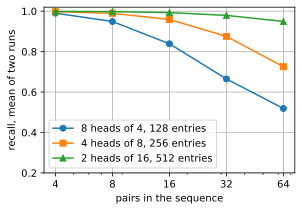

In [16]:
pairs = list(recall[name][0])
d2l.plot(pairs, [[np.mean([run[n] for run in runs]) for n in pairs]
                 for runs in recall.values()], 'pairs in the sequence',
         'recall, mean of two runs', legend=list(recall), xscale='log',
         ylim=(0.2, 1.02), fmts=('-o', '-s', '-^'), figsize=(4.5, 3))
d2l.plt.xticks(pairs, pairs)  # Ticks at the numbers of pairs
print(f'{"pairs":26s}', ''.join(f'{n:>11d}' for n in pairs))
for name, runs in recall.items():
    print(f'{name:26s}', ''.join(f'{runs[0][n]:6.2f}/{runs[1][n]:.2f}'
                                 for n in pairs))

<!-- d2l:prose id=matrix-state-md-17 fw=all -->

All three configurations solve 4 pairs ($\ge 98\%$), and as the pair load grows, recall scales directly with state entries: doubling state capacity from 128 entries ($8 \times 4^2$) to 256 entries ($4 \times 8^2$) roughly doubles the number of pairs recalled at a given accuracy (from $\sim 0.50$ to $\sim 0.75$ at 64 pairs), and 512 entries ($2 \times 16^2$) outperforms 128 entries across all loads $\ge 16$.

One structural flaw remains in every additive matrix memory: writing $\mathbf{v}_t \mathbf{k}_t^\top$ simply *adds* to whatever value is already stored under $\mathbf{k}_t$. If a key is bound a second time to a new value, querying that key returns a superposition of old and new values. Teaching the memory to *overwrite* a key's value is the subject of that section.

## Summary

A matrix-valued state $\mathbf{S}_t \in \mathbb{R}^{d_v \times d_k}$ stores key–value pairs via outer-product writes $\mathbf{v}_t \mathbf{k}_t^\top$ and retrieves them via linear queries $\mathbf{S}_t \mathbf{q}_t$. Unrolled, this recurrence is causal linear attention—and Mamba's selective SSM is an instance with key $\mathbf{B}_t$ and query $\mathbf{C}_t$. Under random unit keys, pairwise cross-talk produces an expected squared retrieval error of $(n - 1)/d_k$ after $n$ writes, while nearest-neighbor recall capacity scales with the total state entries $d_k d_v$. Adding an input-dependent scalar decay $a_t \in (0, 1)$ per head fades old pairs and yields *state space duality* with causally masked linear attention $\mathbf{Y} = (\mathbf{L} \odot \mathbf{Q}\mathbf{K}^\top)\mathbf{V}$. Evaluating this dual form in chunks combines parallel intra-chunk matrix multiplications with an inter-chunk scan in $O(T)$ memory. On multi-query associative recall at fixed parameter count, doubling a `GatedLinearAttention` layer's state entries roughly doubles the number of pairs it can recall, though purely additive writes still cannot overwrite a previously bound key.

## Exercises

1. **Mamba as a matrix memory.** In the form
   $\mathbf{S}_t = \mathbf{E}_t \odot \mathbf{S}_{t-1} +
   (\boldsymbol{\Delta}_t \odot \mathbf{x}_t)\, \mathbf{B}_t^\top$ with
   $\mathbf{E}_t = \exp(\textrm{diag}(\boldsymbol{\Delta}_t)\,
   \boldsymbol{\Lambda})$, the logarithm of the decay is the matrix of
   rates with row $c$ scaled by the step size $\Delta_{t,c}$.
    1. Under which conditions on $\boldsymbol{\Delta}_t$ and on the rates
       $\boldsymbol{\Lambda}$ is $\mathbf{E}_t$ a scalar multiple of the
       matrix of ones, so that the update has the form
       the equation? Which of these conditions does Mamba-2
       impose, and what does it keep input-dependent?
    1. For each form of decay in this section (RetNet, Mamba-2, gated
       linear attention, Mamba), count the input-dependent numbers per
       token that determine the decay of one head of $d_v \times d_k$
       entries.

1. **Rank-one blocks.** Let $p_t = a_1 a_2 \cdots a_t$ be the products of
   the decays in the equation.
    1. Express $L_{ts}$ through the $p_t$, and show that every submatrix of
       $\mathbf{L}$ whose row indices are all at least as large as its
       column indices has rank one.
    1. Deduce that every block of $\mathbf{L} \odot
       \mathbf{Q}\mathbf{K}^\top$ that couples a chunk to an earlier chunk
       has rank at most $d_k$. Identify where `chunked_linear_attention`
       applies the query-side and the key-side decays of such a block.
    1. With a decay per key coordinate, $\mathbf{S}_t = \mathbf{S}_{t-1}
       \textrm{diag}(\boldsymbol{\alpha}_t) + \mathbf{v}_t
       \mathbf{k}_t^\top$, no single mask $\mathbf{L}$ multiplies
       $\mathbf{Q}\mathbf{K}^\top$. Write the decayed score of query $t$
       and key $s$, and show that a block coupling two chunks still has
       rank at most $d_k$.

1. **Counting operations.** Count one multiply-add as two floating-point
   operations, set $d_k = d_v = d$, and keep the leading terms.
    1. Count the operations of the recurrence, the dual form, and the
       chunked form at length $T$ and chunk size $m$. Split the chunked
       count into the three parts of the algorithm.
    1. Show that the chunked form costs at most a small constant times the
       recurrence while $m \le d$, and compute the ratio of chunked to dual
       operations at $T = 4096$, $d = 64$, and $m = 256$.
    1. Model the run time of a schedule as its operations divided by a
       throughput $P$, plus a fixed time $\tau$ per sequential step: $T$
       steps for the recurrence and $T/m$ for the chunked form. Find the
       chunk size that minimizes the chunked time, and evaluate it for
       $T = 4096$, $d = 64$, $P = 10^{13}$ operations per second, and
       $\tau = 5\,\mu\textrm{s}$. How much faster than the recurrence does
       the model predict the chunked form to be?

1. **Correlated keys.** ● The keys with $\rho > 0$ in `matrix_memory` are
   normalized versions of $\sqrt{1-\rho^2}\, \mathbf{g}_i + \rho\,
   \mathbf{c}$, with independent random unit vectors $\mathbf{g}_i$ and
   one shared unit vector $\mathbf{c}$. The formula in the text models
   the overlap of two distinct keys as $\rho^2 + \epsilon_{ij}$, with
   independent $\epsilon_{ij}$ of mean zero and variance $(1-\rho^2)^2/d_k$,
   and assumes values of mean zero.
    1. The values of `matrix_memory` come from a codebook of 256 random
       vectors, whose mean $\bar{\mathbf{v}}$ is not exactly zero. Show
       that this adds a term proportional to $(n-1)(n-2)\,
       \|\bar{\mathbf{v}}\|^2$ to the expected squared error, and compare
       your complete prediction with the measured errors.
    1. Center the codebook (subtract its mean, then normalize each entry
       again) and check that the upward bend of the curve disappears.
    1. Measure the error and the recall for $\rho \in \{0, 0.25, 0.5,
       0.75\}$ at $d_k = 64$ and $d_k = 256$. For which $\rho$ does the
       wider key still help, and where does the error approach $(n-1)
       \rho^4$?

1. [code] **Keys and values of different widths.** ● Give `matrix_memory`
   a value width `d_v` of its own, so that the codebook holds 256 random
   unit vectors in $\mathbb{R}^{d_v}$.
    1. Keep $n/(d_k d_v) = 1/32$ and measure recall for $(d_k, d_v) = (64,
       64)$, $(256, 16)$, and $(16, 256)$. Does recall depend on the product
       $d_k d_v$ alone?
    1. Show that the expected squared read error does not depend on $d_v$,
       so that it cannot explain what you measured.
    1. Every codebook entry is stored under about $n/256$ of the keys. Show
       that their overlaps with the read key add a component of variance
       about $n/(256\, d_k)$ along that entry, and use it to explain for
       which shapes the product law fails.

1. [code] **Decay as a sliding window.** ● Add a constant decay $a$ to
   `matrix_memory`, so that the pair written $\ell$ steps before the end
   enters the final memory with weight $a^\ell$.
    1. At $d_k = 64$ and $n = 256$, measure recall separately for the
       oldest and the newest quarter of the pairs, for $a \in \{1, 0.99,
       0.95, 0.9\}$. What does the decay give the newest pairs, and what
       does it cost the oldest?
    1. Following the proof of the proposition, show that the expected
       squared interference at any key is at most $1 / ((1-a^2)\, d_k)$.
       Show that the number of pairs whose squared signal $a^{2\ell}$
       exceeds this bound is at most about $d_k / e$, whatever $a < 1$ is.

[Discussions](https://d2l.discourse.group/t/36783)